In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/customer_transactions.csv')

display(df.head(10))

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand,lifestage,premium_customer
0,2018-10-17,1,1000,1,5,2,6.0,natural chip compny seasalt 175 g,175,Natural Chip Company,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,3,6.3,ccs nacho cheese 175 g,175,CCs,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,2,2.9,smiths crinkle cut chips chicken 170 g,170,Smith's,MIDAGE SINGLES/COUPLES,Budget
3,2018-08-17,2,2373,974,69,5,15.0,smiths chip thinly s cream onion 175 g,175,Smith's,MIDAGE SINGLES/COUPLES,Budget
4,2018-08-18,2,2426,1038,108,3,13.8,kettle tortilla chpshny jlpno chili 150 g,150,Kettle,MIDAGE SINGLES/COUPLES,Budget
5,2019-05-16,4,4149,3333,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget
6,2019-05-16,4,4196,3539,24,1,3.6,grain waves sweet chilli 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
7,2018-08-20,5,5026,4525,42,1,3.9,doritos corn chip mexican jalapeno 150 g,150,Doritos,MIDAGE SINGLES/COUPLES,Budget
8,2018-08-18,7,7150,6900,52,2,7.2,grain waves sour cream chives 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
9,2019-05-17,7,7215,7176,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget


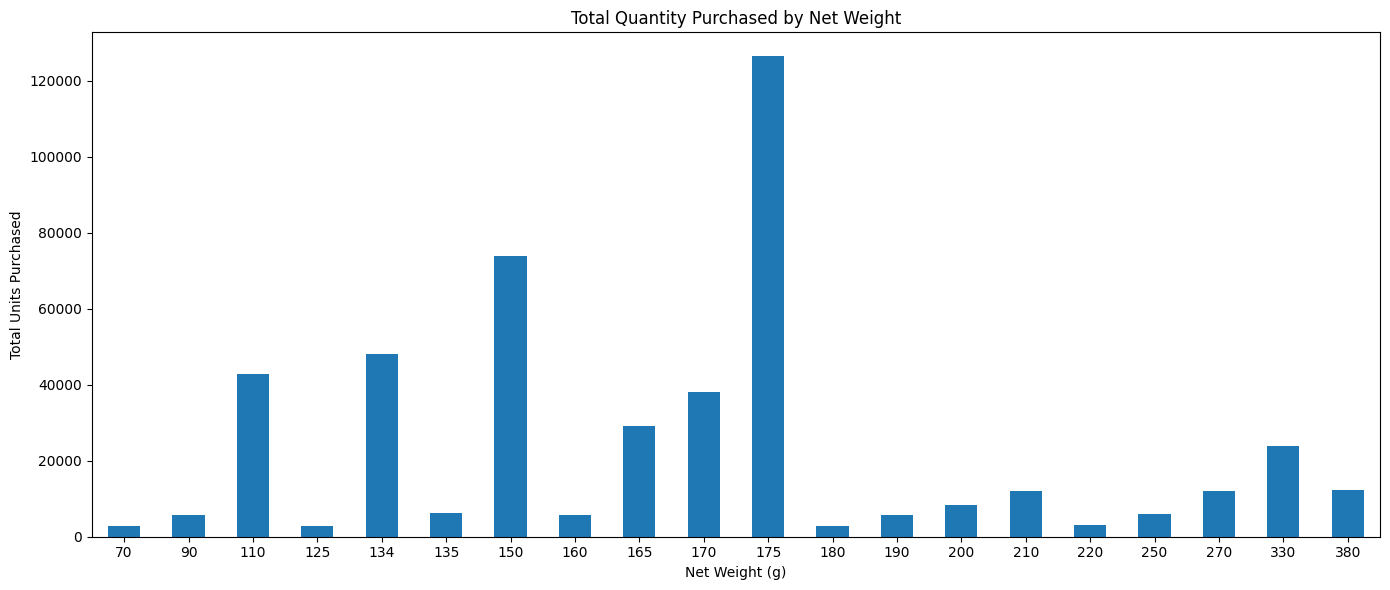

In [5]:
# recall the distribution of net weight across transactions - from the data preprocessing notebook

df.groupby("net_weight")["prod_qty"].sum().sort_index().plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Total Quantity Purchased by Net Weight")
plt.xlabel("Net Weight (g)")
plt.ylabel("Total Units Purchased")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

*in general, small-to-mid sized packets are a lot more popular than larger pack sizes* <br>

- this shows the frequency, so the tapering down on the larger/premium pack sizes is normal. <br>

*now look at the most successful pack sizes based on their raw sales and sales percent share* <br>

In [ ]:
# tally the top 10 net weights by total sales and share of total sales

weight_sales = df.groupby("net_weight")["tot_sales"].sum()

top_weights = (
    weight_sales.nlargest(10)
    .reset_index(name="total_sales")
)
top_weights["sales_share_%"] = top_weights["total_sales"] / weight_sales.sum() * 100

# tidy up the format to show 2 decimal places and a percentage sign
top_weights["sales_share_%"] = top_weights["sales_share_%"].map(lambda v: f"{v:.2f}%")

print(top_weights)

   net_weight  total_sales sales_share_%
0         175     485431.4        27.00%
1         150     282635.8        15.72%
2         134     177655.5         9.88%
3         110     162765.4         9.05%
4         170     146673.0         8.16%
5         330     136794.3         7.61%
6         165     101360.6         5.64%
7         380      75419.6         4.19%
8         270      55425.4         3.08%
9         210      43048.8         2.39%


the 175g and 150g are a slate above the other well-performing pack sizes <br>
- larger pack sizes **[330, 380, 270]** also account for significant sales_share_% despite their low quanitity purchased <br>
            --> proving their premium positioning <br>
- *let's examine whether this disparity of the top 2 net_weights could be due to the product offerrings* {recalling from the data_preparation step}

In [3]:
# compare the number of unique products at the most popular pack size (175g) and a moderately performing pack size (110g)

count_175 = df[df['net_weight'] == 175]['clean_prod_name'].nunique()
count_110 = df[df['net_weight'] == 110]['clean_prod_name'].nunique()

print("net_weight == 175:", count_175)
print("net_weight == 110:", count_110)

net_weight == 175: 30
net_weight == 110: 7


the top 1 net_weight has drastically more unique SKUs compared to the top 4 pack size. 

In [4]:
weight_summary = df.groupby("net_weight").agg(
    total_sales=("tot_sales", "sum"),
    unique_products=("clean_prod_name", "nunique"),
    unique_brands=("brand", "nunique"),
)

all_sales = weight_summary["total_sales"].sum()

top_weights = weight_summary.nlargest(10, "total_sales").reset_index()
top_weights["sales_share_%"] = top_weights["total_sales"] / all_sales * 100

# 5 columns: net_weight, total_sales, sales_share_%, unique_products, unique_brands
top_weights = top_weights[
    ["net_weight", "total_sales", "sales_share_%", "unique_products", "unique_brands"]
]

# tidy up the format to show 2 decimal places and a percentage sign
top_weights["sales_share_%"] = top_weights["sales_share_%"].map(lambda v: f"{v:.2f}%")

print(top_weights)

   net_weight  total_sales sales_share_%  unique_products  unique_brands
0         175     485431.4        27.00%               30              8
1         150     282635.8        15.72%               17              4
2         134     177655.5         9.88%                8              1
3         110     162765.4         9.05%                7              2
4         170     146673.0         8.16%                9              2
5         330     136794.3         7.61%                4              3
6         165     101360.6         5.64%                8              3
7         380      75419.6         4.19%                2              2
8         270      55425.4         3.08%                2              1
9         210      43048.8         2.39%                2              1


this result should explain the standout performance of 175g and 150g pack sizes. *there are more brands and SKUs that come in this weight* <br>

**175g and 150g are most bought due to the sheer number of chips in their configuration** <br>

- with that out of the way, let's look at the size preferences of each cohort.

In [ ]:
# 1. Families segment: older families + young families
families_lifestages = ["OLDER FAMILIES", "YOUNG FAMILIES"]
families = df[df["lifestage"].isin(families_lifestages)]
other_segments = df[~df["lifestage"].isin(families_lifestages)]

# 2. net_weight affinity
value_col = "prod_qty"   # swap to "tot_sales" to measure affinity by sales instead

families_share = families.groupby("net_weight")[value_col].sum() / families[value_col].sum()
other_share = other_segments.groupby("net_weight")[value_col].sum() / other_segments[value_col].sum()

net_weight_affinity = pd.DataFrame({
    "families_share": families_share,
    "other_share": other_share,
})
net_weight_affinity["affinity_to_net_weight"] = (
    net_weight_affinity["families_share"] / net_weight_affinity["other_share"]
)

net_weight_affinity = net_weight_affinity.sort_values("affinity_to_net_weight", ascending=False)
display(net_weight_affinity)

,families_share,other_share,affinity_to_net_weight
net_weight,,,
180,0.007159,0.005226,1.369821
220,0.007589,0.005673,1.337670
200,0.021526,0.016093,1.337631
190,0.014488,0.010840,1.336533
90,0.014391,0.010956,1.313578
160,0.013587,0.011105,1.223548
70,0.006893,0.005673,1.215094
125,0.006440,0.005508,1.169243
165,0.067324,0.059267,1.135940


In [11]:
# 1. Families segment: older families + young families
youngfamilies_lifestages =  ["YOUNG FAMILIES"]
youngfamilies = df[df["lifestage"].isin(youngfamilies_lifestages)]
other_segments = df[~df["lifestage"].isin(youngfamilies_lifestages)]

# 2. net_weight affinity
value_col = "prod_qty"   # swap to "tot_sales" to measure affinity by sales instead

youngfamilies_share = youngfamilies.groupby("net_weight")[value_col].sum() / youngfamilies[value_col].sum()
other_share = other_segments.groupby("net_weight")[value_col].sum() / other_segments[value_col].sum()

net_weight_affinity = pd.DataFrame({
    "youngfamilies_share": youngfamilies_share,
    "other_share": other_share,
})
net_weight_affinity["affinity_to_net_weight"] = (
    net_weight_affinity["youngfamilies_share"] / net_weight_affinity["other_share"]
)

net_weight_affinity = net_weight_affinity.sort_values("affinity_to_net_weight", ascending=False)
display(net_weight_affinity)

,youngfamilies_share,other_share,affinity_to_net_weight
net_weight,,,
90,0.015042,0.011595,1.297286
190,0.014351,0.011685,1.228102
200,0.020898,0.017437,1.198512
220,0.007355,0.006149,1.196022
180,0.006778,0.005736,1.181659
70,0.006791,0.005967,1.138065
165,0.067614,0.061015,1.108151
160,0.012980,0.011783,1.101580
125,0.006253,0.005754,1.086671


In [12]:
# 1. Families segment: older families + young families
olderfamilies_lifestages =  ["OLDER FAMILIES"]
olderfamilies = df[df["lifestage"].isin(olderfamilies_lifestages)]
other_segments = df[~df["lifestage"].isin(olderfamilies_lifestages)]

# 2. net_weight affinity
value_col = "prod_qty"   # swap to "tot_sales" to measure affinity by sales instead

olderfamilies_share = olderfamilies.groupby("net_weight")[value_col].sum() / olderfamilies[value_col].sum()
other_share = other_segments.groupby("net_weight")[value_col].sum() / other_segments[value_col].sum()

net_weight_affinity = pd.DataFrame({
    "olderfamilies_share": olderfamilies_share,
    "other_share": other_share,
})
net_weight_affinity["affinity_to_net_weight"] = (
    net_weight_affinity["olderfamilies_share"] / net_weight_affinity["other_share"]
)

net_weight_affinity = net_weight_affinity.sort_values("affinity_to_net_weight", ascending=False)
display(net_weight_affinity)

,olderfamilies_share,other_share,affinity_to_net_weight
net_weight,,,
180,0.007500,0.005545,1.352615
220,0.007798,0.006018,1.295719
200,0.022088,0.017079,1.293290
190,0.014611,0.011560,1.263874
160,0.014130,0.011489,1.229825
70,0.006985,0.005902,1.183377
90,0.013809,0.011794,1.170840
125,0.006607,0.005661,1.167190
165,0.067065,0.060980,1.099789


In [16]:
# 1. Families segment: budget tier of older families + young families
families_lifestages = ["OLDER FAMILIES", "YOUNG FAMILIES"]
families = df[
    df["lifestage"].isin(families_lifestages) & (df["premium_customer"] == "Budget")
]
other_segments = df[~df["lifestage"].isin(families_lifestages)]

# 2. net_weight affinity
value_col = "prod_qty"   # swap to "tot_sales" to measure affinity by sales instead

families_share = families.groupby("net_weight")[value_col].sum() / families[value_col].sum()
other_share = other_segments.groupby("net_weight")[value_col].sum() / other_segments[value_col].sum()

net_weight_affinity = pd.DataFrame({
    "families_share": families_share,
    "other_share": other_share,
})
net_weight_affinity["affinity_to_net_weight"] = (
    net_weight_affinity["families_share"] / net_weight_affinity["other_share"]
)

net_weight_affinity = net_weight_affinity.sort_values("affinity_to_net_weight", ascending=False)
display(net_weight_affinity)

,families_share,other_share,affinity_to_net_weight
net_weight,,,
180,0.007491,0.005226,1.433328
190,0.014231,0.010840,1.312803
90,0.014349,0.010956,1.309764
200,0.020812,0.016093,1.293238
220,0.007148,0.005673,1.260055
160,0.013611,0.011105,1.225696
70,0.006805,0.005673,1.199610
125,0.006568,0.005508,1.192531
165,0.064678,0.059267,1.091288


focusing on the standout tiers from family-based lifestages, we find a strong shared affinity for medium-sized chips, with exceptions of [90, 70, and 125]

- budget family cohorts prefer medium-sized chips, with a handful of small-sized exceptions. 

In [17]:
retirees_lifestages = ["RETIREES"]
retirees = df[
    df["lifestage"].isin(retirees_lifestages) & (df["premium_customer"] == "Mainstream")
]
other_segments = df[~df["lifestage"].isin(retirees_lifestages)]

# 2. net_weight affinity
value_col = "prod_qty"   # swap to "tot_sales" to measure affinity by sales instead

retirees_share = retirees.groupby("net_weight")[value_col].sum() / retirees[value_col].sum()
other_share = other_segments.groupby("net_weight")[value_col].sum() / other_segments[value_col].sum()

net_weight_affinity = pd.DataFrame({
    "retirees_share": retirees_share,
    "other_share": other_share,
})
net_weight_affinity["affinity_to_net_weight"] = (
    net_weight_affinity["retirees_share"] / net_weight_affinity["other_share"]
)

net_weight_affinity = net_weight_affinity.sort_values("affinity_to_net_weight", ascending=False)
display(net_weight_affinity)

,retirees_share,other_share,affinity_to_net_weight
net_weight,,,
250,0.014618,0.012618,1.158464
210,0.027449,0.025353,1.082681
70,0.006642,0.006191,1.072889
134,0.106567,0.101481,1.050117
110,0.092963,0.090928,1.022387
150,0.160211,0.158120,1.013227
170,0.082426,0.081439,1.012128
125,0.006002,0.005933,1.011592
270,0.025822,0.025605,1.008456


pack size is a tricky field to see trends across target segments. preferences are scattered and is not limited to one cohort preferrring only medium sizes. 

*pack size could be a good secondary filter for preference, but is not a standalone metric*